# Clasificacion de imagenes con CIFAR-10
## Notebook base en PyTorch

Este notebook introduce el flujo completo de un proyecto de vision por
computadora con imagenes a color. Usamos CIFAR-10, uno de los datasets
clasicos mas utilizados en Deep Learning.

## Que es CIFAR-10

CIFAR-10 fue creado por el Canadian Institute for Advanced Research.
Sus caracteristicas son:

- 60.000 imagenes a color de 32x32 pixeles.
- 50.000 para entrenamiento y 10.000 para test.
- 3 canales (RGB).
- 10 clases de objetos del mundo real.

Las 10 clases son:

| Indice | Clase |
|---|---|
| 0 | Airplane |
| 1 | Automobile |
| 2 | Bird |
| 3 | Cat |
| 4 | Deer |
| 5 | Dog |
| 6 | Frog |
| 7 | Horse |
| 8 | Ship |
| 9 | Truck |

## Por que es importante

- Es el siguiente paso natural despues de MNIST y Fashion-MNIST.
- Introduce imagenes a color, lo que obliga a manejar 3 canales.
- Los objetos son mas variados y complejos: el modelo debe aprender
  formas, texturas y contextos distintos.
- Es un benchmark estandar: permite comparar con la literatura.
- El accuracy humano ronda el 94 por ciento. Una CNN bien disenada
  alcanza entre 75 y 90 por ciento.

## Diferencia con Fashion-MNIST

| Aspecto | Fashion-MNIST | CIFAR-10 |
|---|---|---|
| Canales | 1 (gris) | 3 (RGB) |
| Tamano | 28x28 | 32x32 |
| Clases | 10 prendas | 10 objetos |
| Dificultad | Media | Alta |
| Accuracy tipico | 92 por ciento | 75 a 90 por ciento |

## Objetivos del notebook

Al finalizar, seras capaz de:

1. Cargar y explorar un dataset de imagenes a color.
2. Aplicar normalizacion especifica por canal.
3. Definir una CNN mas profunda con BatchNorm y Dropout.
4. Entrenar con validacion y early stopping.
5. Evaluar con metricas robustas y matriz de confusion.
6. Visualizar filtros y feature maps.
7. Analizar errores y comparar con y sin data augmentation.

## Configuracion inicial

Importamos librerias, fijamos semillas y detectamos GPU.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Dispositivo:", device)

PyTorch version: 2.7.1+cpu
Dispositivo: cpu


# 1. Carga del dataset

## Normalizacion por canal

A diferencia de Fashion-MNIST, CIFAR-10 tiene 3 canales (R, G, B). Cada
canal tiene su propia media y desviacion estandar. Usar valores
especificos por canal mejora el entrenamiento.

Los valores estandar reportados para CIFAR-10 son:

- Media: (0.4914, 0.4822, 0.4465)
- Desviacion estandar: (0.2470, 0.2435, 0.2616)

## Transformaciones

Definimos dos transformaciones:

- `transform_train`: con data augmentation. Aplicamos volteo
  horizontal aleatorio y recorte aleatorio con padding. Estas tecnicas
  son casi obligatorias en CIFAR-10 porque el dataset es pequeno y el
  modelo tiende a sobreajustarse.
- `transform_test`: sin augmentation. Solo conversion a tensor y
  normalizacion. La evaluacion debe ser deterministica.

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform_train,
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform_test,
)

print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

100%|███████████████████████████████████████████████████████████████████████████████| 170M/170M [30:54<00:00, 91.9kB/s]


Train size: 50000
Test size: 10000


## Nombres de las clases

In [3]:
clases = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck",
]

# 2. Exploracion del dataset

## Inspeccion de una muestra

Cada imagen tiene shape (3, 32, 32). Los valores ya estan normalizados.

In [4]:
imagen, etiqueta = train_dataset[0]
print("Shape de la imagen:", imagen.shape)
print("Etiqueta:", etiqueta)
print("Clase:", clases[etiqueta])
print("Valor minimo:", imagen.min().item())
print("Valor maximo:", imagen.max().item())

Shape de la imagen: torch.Size([3, 32, 32])
Etiqueta: 6
Clase: Frog
Valor minimo: -1.9894737005233765
Valor maximo: 2.094278573989868


## Visualizacion de ejemplos

Mostramos una imagen por clase. Importante: como las imagenes estan
normalizadas, hay que desnormalizarlas para verlas correctamente.

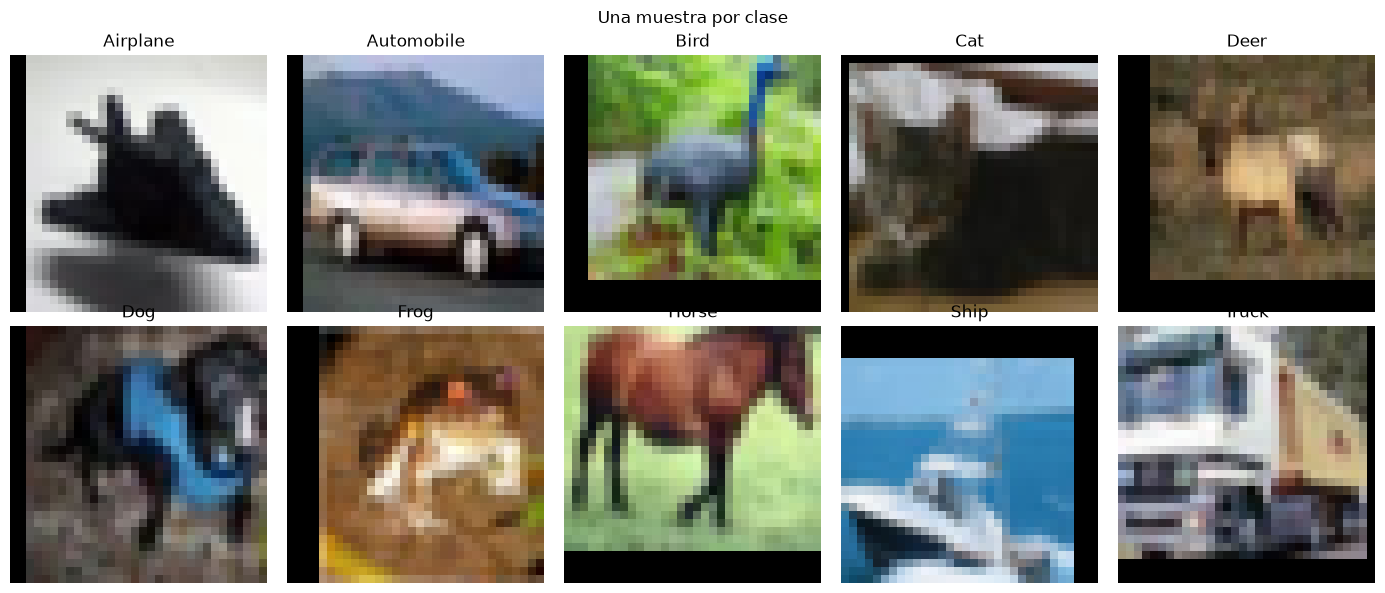

In [5]:
def desnormalizar(imagen, mean, std):
    img = imagen.clone()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    return img.clamp(0, 1)


fig, axes = plt.subplots(2, 5, figsize=(14, 6))
contador = {i: 0 for i in range(10)}

for imagen, etiqueta in train_dataset:
    if contador[etiqueta] == 0:
        ax = axes[etiqueta // 5, etiqueta % 5]
        img_vis = desnormalizar(imagen, mean, std).permute(1, 2, 0)
        ax.imshow(img_vis)
        ax.set_title(clases[etiqueta])
        ax.axis("off")
        contador[etiqueta] += 1
    if all(v > 0 for v in contador.values()):
        break

plt.suptitle("Una muestra por clase")
plt.tight_layout()
plt.show()

## Distribucion de clases

CIFAR-10 esta balanceado: 6.000 imagenes por clase en el conjunto
completo, 5.000 en train.

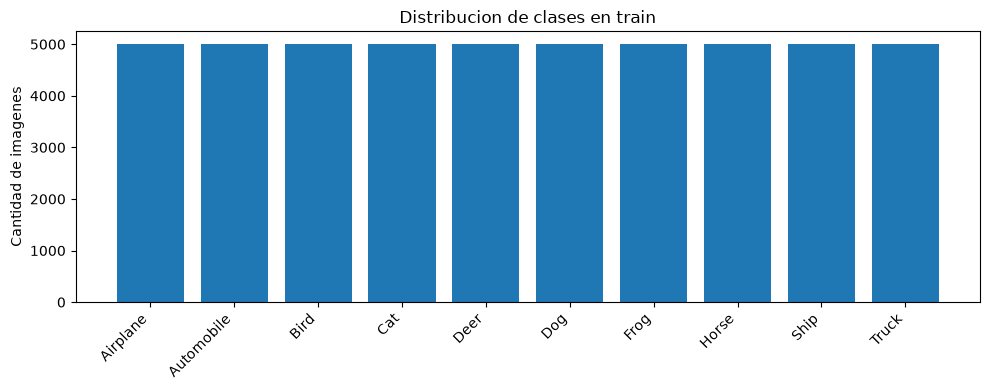

    Airplane: 5000 imagenes
  Automobile: 5000 imagenes
        Bird: 5000 imagenes
         Cat: 5000 imagenes
        Deer: 5000 imagenes
         Dog: 5000 imagenes
        Frog: 5000 imagenes
       Horse: 5000 imagenes
        Ship: 5000 imagenes
       Truck: 5000 imagenes


In [6]:
etiquetas_train = [etiqueta for _, etiqueta in train_dataset]
conteo = np.bincount(etiquetas_train)

plt.figure(figsize=(10, 4))
plt.bar(clases, conteo)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Cantidad de imagenes")
plt.title("Distribucion de clases en train")
plt.tight_layout()
plt.show()

for i, c in enumerate(clases):
    print(f"{c:>12}: {conteo[i]} imagenes")

# 3. Division train / validation / test

Separamos 5.000 imagenes para validacion. El test se mantiene intacto.

In [7]:
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

print("Train:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_dataset))

Train: 45000
Validation: 5000
Test: 10000


## DataLoaders

In [8]:
batch_size = 64

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

X_batch, y_batch = next(iter(train_loader))
print("Shape del batch de imagenes:", X_batch.shape)
print("Shape del batch de etiquetas:", y_batch.shape)

Shape del batch de imagenes: torch.Size([64, 3, 32, 32])
Shape del batch de etiquetas: torch.Size([64])


# 4. Definicion de la CNN

## Arquitectura

Para CIFAR-10 necesitamos una red mas profunda que para Fashion-MNIST.
Introducimos dos tecnicas clave:

- **Batch Normalization**: normaliza las activaciones dentro de la red.
  Acelera el entrenamiento, permite learning rates mas altos y actua
  como regularizador.
- **Dropout**: apaga neuronas aleatoriamente para reducir overfitting.

| Capa | Configuracion | Salida |
|---|---|---|
| Conv1 | Conv2d(3, 32, 3, padding=1) + BN + ReLU | (32, 32, 32) |
| Conv2 | Conv2d(32, 32, 3, padding=1) + BN + ReLU | (32, 32, 32) |
| Pool1 | MaxPool2d(2) | (32, 16, 16) |
| Conv3 | Conv2d(32, 64, 3, padding=1) + BN + ReLU | (64, 16, 16) |
| Conv4 | Conv2d(64, 64, 3, padding=1) + BN + ReLU | (64, 16, 16) |
| Pool2 | MaxPool2d(2) | (64, 8, 8) |
| Conv5 | Conv2d(64, 128, 3, padding=1) + BN + ReLU | (128, 8, 8) |
| Pool3 | MaxPool2d(2) | (128, 4, 4) |
| Flatten | - | 128*4*4 = 2048 |
| FC1 | Linear(2048, 256) + ReLU | 256 |
| Dropout | Dropout(0.4) | 256 |
| FC2 | Linear(256, 10) | 10 |

## Por que BatchNorm

Sin BatchNorm, las activaciones pueden tener distribuciones que cambian
mucho entre capas, lo que dificulta el entrenamiento. BatchNorm
estabiliza estas distribuciones y permite entrenar redes mas profundas
de forma mas rapida y estable.

In [9]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)
        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        x = F.relu(self.bn5(self.conv5(x)))
        x = self.pool(x)

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


modelo = CNN().to(device)
print(modelo)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=2048, ou

## Conteo de parametros

In [10]:
def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parametros totales: {total:,}")
    print(f"Parametros entrenables: {entrenables:,}")

contar_parametros(modelo)

Parametros totales: 667,178
Parametros entrenables: 667,178


# 5. Entrenamiento

## Configuracion

- **Loss**: CrossEntropyLoss.
- **Optimizer**: Adam con lr = 0.001.
- **Scheduler**: `ReduceLROnPlateau`. Reduce el learning rate cuando la
  validation loss deja de mejorar. Es una tecnica muy util en CIFAR-10.
- **Epochs**: 20. Con early stopping por paciencia de 5.

## Por que un scheduler

Al inicio del entrenamiento, un learning rate alto ayuda a explorar. Al
final, un learning rate menor permite afinar los pesos. El scheduler
automatiza este ajuste.

In [11]:
def entrenar(modelo, train_loader, val_loader, epochs=20, lr=0.001, patience=5):
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    loss_fn = nn.CrossEntropyLoss()

    historial_train = []
    historial_val = []
    mejor_val = float("inf")
    mejor_epoch = 0
    epochs_sin_mejora = 0

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = modelo(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            perdida_total += loss.item() * X_batch.size(0)
        train_loss = perdida_total / len(train_loader.dataset)
        historial_train.append(train_loss)

        modelo.eval()
        perdida_val = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                logits = modelo(X_batch)
                loss = loss_fn(logits, y_batch)
                perdida_val += loss.item() * X_batch.size(0)
        val_loss = perdida_val / len(val_loader.dataset)
        historial_val.append(val_loss)

        lr_actual = optimizer.param_groups[0]["lr"]
        print(f"Epoch {epoch+1:>2}/{epochs} | "
              f"train: {train_loss:.4f} | val: {val_loss:.4f} | lr: {lr_actual:.6f}")

        scheduler.step(val_loss)

        if val_loss < mejor_val:
            mejor_val = val_loss
            mejor_epoch = epoch
            epochs_sin_mejora = 0
        else:
            epochs_sin_mejora += 1
            if epochs_sin_mejora >= patience:
                print(f"Early stopping en epoch {epoch+1}. "
                      f"Mejor epoch: {mejor_epoch+1} con val loss {mejor_val:.4f}")
                break

    return historial_train, historial_val, mejor_epoch


historial_train, historial_val, mejor_epoch = entrenar(
    modelo, train_loader, val_loader, epochs=20, lr=0.001, patience=5
)

Epoch  1/20 | train: 1.5188 | val: 1.5162 | lr: 0.001000
Epoch  2/20 | train: 1.1488 | val: 1.0329 | lr: 0.001000
Epoch  3/20 | train: 1.0077 | val: 0.8811 | lr: 0.001000
Epoch  4/20 | train: 0.9105 | val: 0.9066 | lr: 0.001000
Epoch  5/20 | train: 0.8407 | val: 0.7702 | lr: 0.001000
Epoch  6/20 | train: 0.7947 | val: 0.7102 | lr: 0.001000
Epoch  7/20 | train: 0.7534 | val: 0.7826 | lr: 0.001000
Epoch  8/20 | train: 0.7168 | val: 0.6266 | lr: 0.001000
Epoch  9/20 | train: 0.6802 | val: 0.6645 | lr: 0.001000
Epoch 10/20 | train: 0.6542 | val: 0.6200 | lr: 0.001000
Epoch 11/20 | train: 0.6265 | val: 0.5780 | lr: 0.001000
Epoch 12/20 | train: 0.5929 | val: 0.5597 | lr: 0.001000
Epoch 13/20 | train: 0.5779 | val: 0.5589 | lr: 0.001000
Epoch 14/20 | train: 0.5582 | val: 0.5474 | lr: 0.001000
Epoch 15/20 | train: 0.5447 | val: 0.5043 | lr: 0.001000
Epoch 16/20 | train: 0.5272 | val: 0.4959 | lr: 0.001000
Epoch 17/20 | train: 0.5085 | val: 0.4861 | lr: 0.001000
Epoch 18/20 | train: 0.5006 | v

## Curvas de aprendizaje

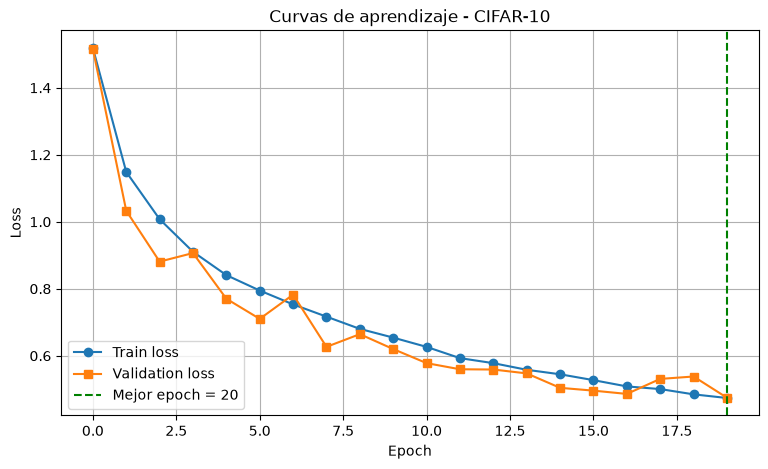

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(historial_train, marker="o", label="Train loss")
plt.plot(historial_val, marker="s", label="Validation loss")
plt.axvline(mejor_epoch, color="green", linestyle="--",
            label=f"Mejor epoch = {mejor_epoch+1}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curvas de aprendizaje - CIFAR-10")
plt.legend()
plt.grid(True)
plt.show()

## Interpretacion

En CIFAR-10 es comun ver:

- Train loss baja de forma sostenida.
- Validation loss baja al inicio y luego se estanca.
- La diferencia entre ambas indica cierto nivel de overfitting,
  esperable con 50.000 imagenes.
- El scheduler reduce el learning rate cuando la validation loss se
  estanca, lo que ayuda a afinar el modelo.

# 6. Evaluacion en test

In [13]:
def obtener_predicciones(modelo, loader):
    modelo.eval()
    todas_pred = []
    todas_etiquetas = []
    todas_probs = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = modelo(X_batch)
            probs = F.softmax(logits, dim=1)
            pred = logits.argmax(dim=1)
            todas_pred.append(pred.cpu().numpy())
            todas_etiquetas.append(y_batch.numpy())
            todas_probs.append(probs.cpu().numpy())
    return (
        np.concatenate(todas_pred),
        np.concatenate(todas_etiquetas),
        np.concatenate(todas_probs),
    )


y_pred, y_true, y_probs = obtener_predicciones(modelo, test_loader)

accuracy = (y_pred == y_true).mean()
print(f"Accuracy en test: {accuracy:.4f}")
print()
print("Reporte por clase:")
print(classification_report(y_true, y_pred, target_names=clases, digits=4))

Accuracy en test: 0.8424

Reporte por clase:
              precision    recall  f1-score   support

    Airplane     0.8745    0.8150    0.8437      1000
  Automobile     0.9163    0.9410    0.9285      1000
        Bird     0.8022    0.7910    0.7966      1000
         Cat     0.7491    0.6480    0.6949      1000
        Deer     0.8249    0.8480    0.8363      1000
         Dog     0.7216    0.8320    0.7729      1000
        Frog     0.9188    0.8370    0.8760      1000
       Horse     0.8773    0.8720    0.8746      1000
        Ship     0.8346    0.9540    0.8903      1000
       Truck     0.9220    0.8860    0.9036      1000

    accuracy                         0.8424     10000
   macro avg     0.8441    0.8424    0.8417     10000
weighted avg     0.8441    0.8424    0.8417     10000



## Matriz de confusion

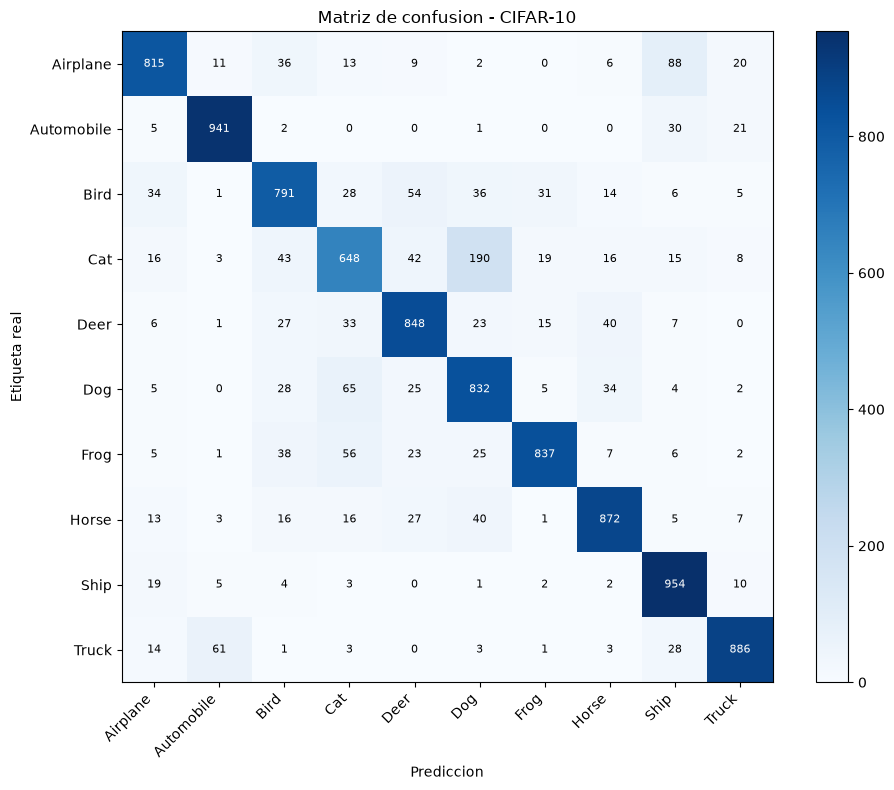

In [14]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), clases, rotation=45, ha="right")
plt.yticks(range(10), clases)
plt.xlabel("Prediccion")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusion - CIFAR-10")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black",
                 fontsize=8)
plt.tight_layout()
plt.show()

## Observaciones tipicas

En CIFAR-10 los errores mas frecuentes son:

- Cat vs. Dog: son visualmente similares y muy variados.
- Deer vs. Horse: cuadrupedos en posiciones parecidas.
- Automobile vs. Truck: vehiculos con formas similares.
- Airplane vs. Ship: fondos azules (cielo vs. mar).

Estas confusiones son esperables. Un accuracy de 75 a 85 por ciento es
un buen resultado con una CNN entrenada desde cero.

# 7. Visualizacion de filtros

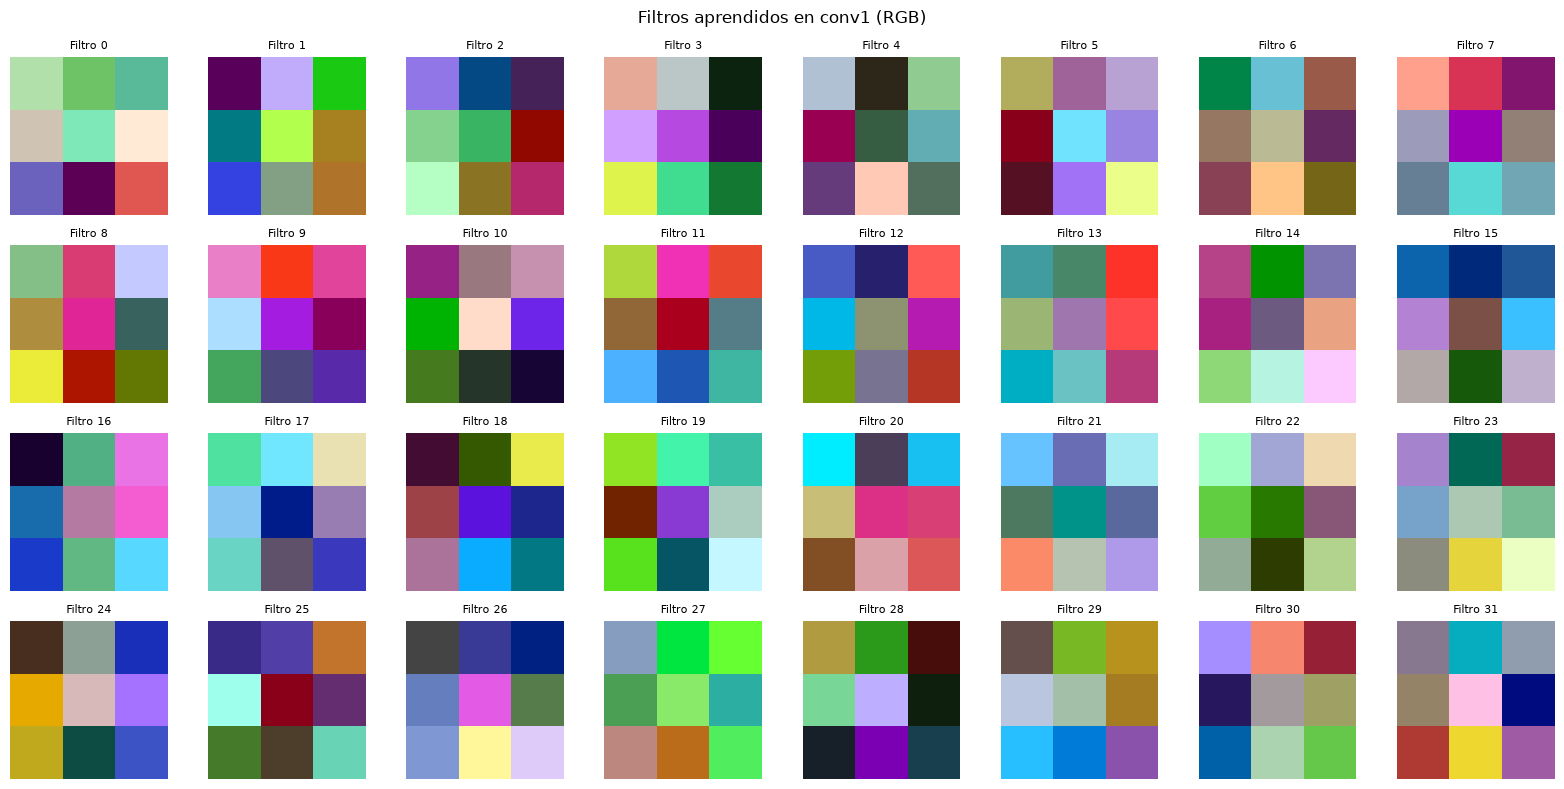

In [15]:
filtros = modelo.conv1.weight.detach().cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    if i < filtros.shape[0]:
        filtro = filtros[i].permute(1, 2, 0)
        filtro = (filtro - filtro.min()) / (filtro.max() - filtro.min() + 1e-8)
        ax.imshow(filtro)
        ax.set_title(f"Filtro {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Filtros aprendidos en conv1 (RGB)")
plt.tight_layout()
plt.show()

## Interpretacion

En la primera capa, los filtros suelen aprender:

- Detectores de bordes en distintas orientaciones.
- Detectores de color (contrastes entre canales).
- Texturas simples.

En capas mas profundas, los filtros detectan patrones mas complejos
como ojos, ruedas, alas, etc.

# 8. Visualizacion de feature maps

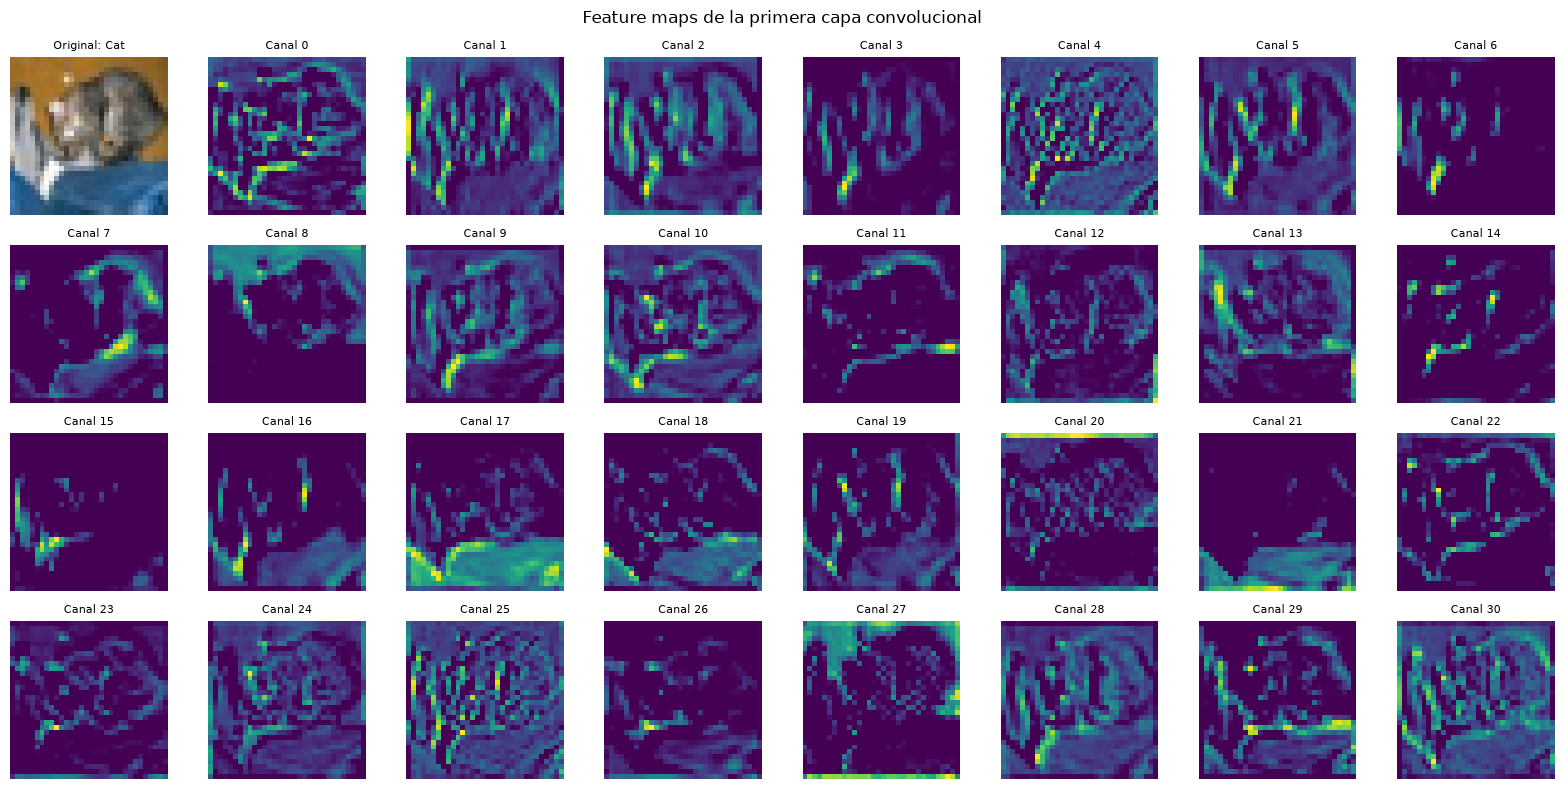

In [16]:
imagen, etiqueta = test_dataset[0]
imagen_tensor = imagen.unsqueeze(0).to(device)

with torch.no_grad():
    activaciones = F.relu(modelo.bn1(modelo.conv1(imagen_tensor))).cpu().squeeze(0)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes[0, 0].imshow(desnormalizar(imagen, mean, std).permute(1, 2, 0))
axes[0, 0].set_title(f"Original: {clases[etiqueta]}", fontsize=8)
axes[0, 0].axis("off")

for i, ax in enumerate(axes.flat[1:]):
    if i < activaciones.shape[0]:
        ax.imshow(activaciones[i], cmap="viridis")
        ax.set_title(f"Canal {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Feature maps de la primera capa convolucional")
plt.tight_layout()
plt.show()

# 9. Analisis de errores

Total de errores en test: 1576 de 10000



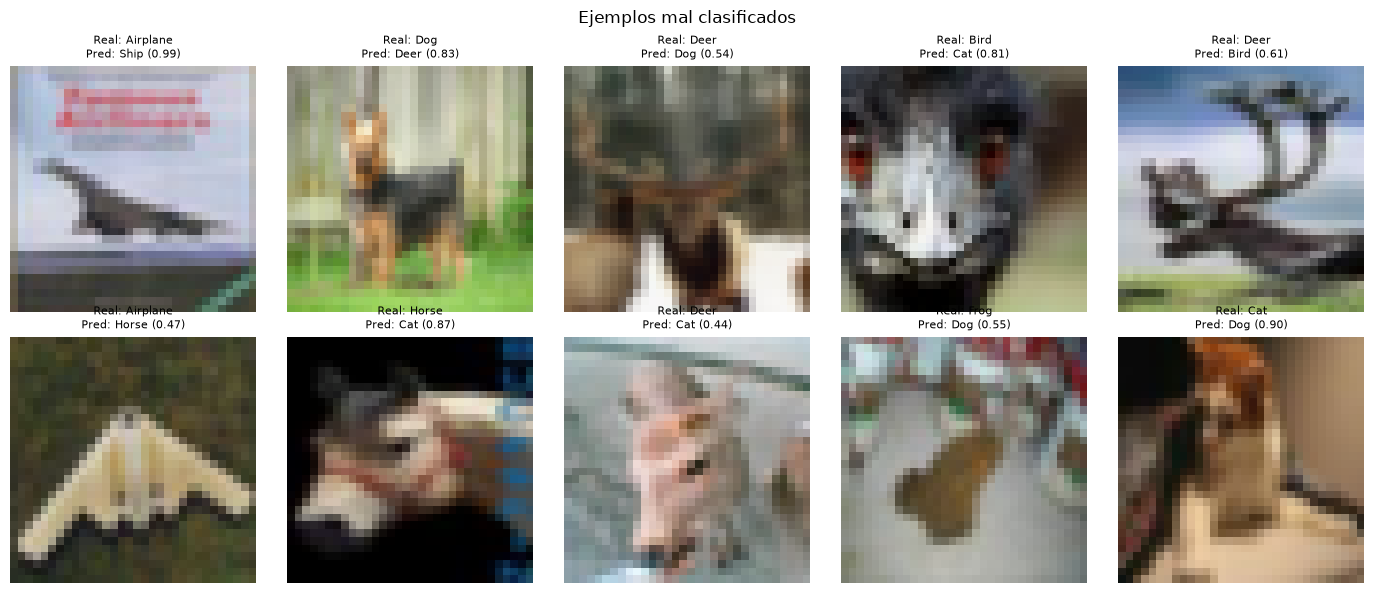

In [17]:
indices_error = np.where(y_pred != y_true)[0]
print(f"Total de errores en test: {len(indices_error)} de {len(y_true)}")
print()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    if i < 10:
        idx = indices_error[i]
        img, _ = test_dataset[idx]
        img_vis = desnormalizar(img, mean, std).permute(1, 2, 0)
        ax.imshow(img_vis)
        prob_pred = y_probs[idx, y_pred[idx]]
        ax.set_title(
            f"Real: {clases[y_true[idx]]}\n"
            f"Pred: {clases[y_pred[idx]]} ({prob_pred:.2f})",
            fontsize=8,
        )
    ax.axis("off")
plt.suptitle("Ejemplos mal clasificados")
plt.tight_layout()
plt.show()

## Preguntas para reflexionar

1. Muchos errores ocurren entre clases visualmente similares.
2. Algunas imagenes son ambiguas incluso para un humano (32x32 es muy
   pequeno).
3. La probabilidad asignada a la clase incorrecta suele ser cercana a
   la de la clase correcta en los errores.
4. Para mejorar el accuracy se puede: aumentar la profundidad, usar
   data augmentation mas agresivo, aplicar transfer learning o
   entrenar por mas epochs.

# 10. Resumen

## Lo que hicimos

- Cargamos y exploramos CIFAR-10.
- Aplicamos normalizacion por canal y data augmentation.
- Dividimos en train, validation y test.
- Definimos una CNN con 5 capas convolucionales, BatchNorm, Dropout y
  dos capas fully connected.
- Entrenamos con Adam, scheduler y early stopping.
- Evaluamos con accuracy, precision, recall, F1 y matriz de confusion.
- Visualizamos filtros y feature maps.
- Analizamos errores.

## Resultados esperados

- Accuracy en test: 75 a 85 por ciento con esta arquitectura y 20
  epochs.
- Las confusiones mas comunes ocurren entre cat/dog, deer/horse y
  automobile/truck.

## Diferencias clave respecto a Fashion-MNIST

- Imagenes a color: 3 canales en lugar de 1.
- Mayor dificultad: requiere arquitectura mas profunda.
- Data augmentation es casi obligatorio.
- BatchNorm acelera y estabiliza el entrenamiento.
- El accuracy es mas bajo: no es un fracaso, es la naturaleza del
  dataset.

## Proximos pasos

- ImageNette: subconjunto de ImageNet para transfer learning.
- Arquitecturas clasicas: VGG, ResNet, DenseNet.
- Data augmentation avanzado: Cutout, Mixup, RandAugment.
- Regularizacion adicional: weight decay, label smoothing.

## Referencias

- CIFAR-10 paper: https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf
- Documentacion de torchvision: https://pytorch.org/vision/stable/
- Documentacion de PyTorch: https://pytorch.org/docs/stable/